# Solutions to the exercises of Chapter 6

**Chapter:** [6. Stochastic thermostats: Andersen and Langevin (BAOAB) dynamics](../../notebooks/part2_ensembles/06_andersen_and_langevin_baoab.ipynb)

Each solution below reproduces the chapter state and verifies the exercise targets with explicit `assert` checks.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

In [2]:
f_ho = lambda p, L: (-p, 0.5 * float(np.sum(p * p)), 0.0)
dts_ho = np.array([0.05, 0.15, 0.30, 0.50])
x2_baoab = []
for dt_v in dts_ho:
    p_a, v_a, f_a = np.array([[0.0]]), np.array([[0.0]]), np.array([[0.0]])
    xs = []
    for st in range(8000):
        p_a, v_a, f_a, _, _, _ = es.baoab_langevin_step(p_a, v_a, f_a, float(dt_v), None, 1.0, 1.0, f_ho, rng)
        if st >= 1500:
            xs.append(float(p_a[0, 0]))
    x2_baoab.append(float(np.mean(np.array(xs)**2)))

BAOAB <x^2> across dt = [0.05..0.50]: [0.992 0.978 0.97  0.993] (exact = 1.000)


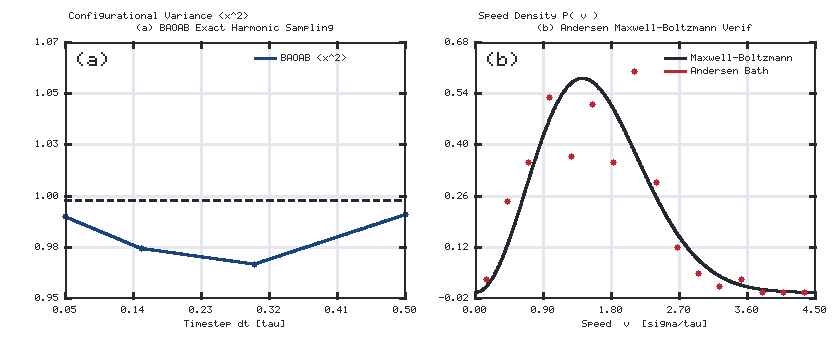

In [3]:
print("BAOAB <x^2> across dt = [0.05..0.50]:", np.round(x2_baoab, 3), "(exact = 1.000)")
assert np.allclose(x2_baoab, 1.0, rtol=0.12)

# Andersen thermostat Maxwell-Boltzmann speed check
v_and = es.init_velocities(200, 1.0, rng=rng)
for _ in range(100):
    v_and = es.andersen_thermostat(v_and, 1.0, dt=0.01, nu=10.0, rng=rng)
speeds = np.linalg.norm(v_and, axis=1)
assert np.isclose(np.mean(speeds**2), 3.0, rtol=0.15)

s_grid = np.linspace(0.0, 4.5, 60)
mb_exact = np.sqrt(2.0 / np.pi) * (s_grid**2) * np.exp(-0.5 * s_grid**2)
h_s, e_s = np.histogram(speeds, bins=16, range=(0, 4.5), density=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(dts_ho, x2_baoab, "bo-", label="BAOAB <x^2>")
ax1.axhline(1.0, color="k")
ax1.set_xlabel("Timestep dt [tau]"); ax1.set_ylabel("Configurational Variance <x^2>")
ax1.set_title("(a) BAOAB Exact Harmonic Sampling"); panel_label(ax1, "(a)")

ax2.plot(s_grid, mb_exact, "k-", label="Maxwell-Boltzmann")
ax2.plot(0.5*(e_s[:-1]+e_s[1:]), h_s, "ro", label="Andersen Bath")
ax2.set_xlabel("Speed |v| [sigma/tau]"); ax2.set_ylabel("Speed Density P(|v|)")
ax2.set_title("(b) Andersen Maxwell–Boltzmann Verification"); panel_label(ax2, "(b)")
plt.show()

## Worked solutions to Exercises 1–3

In [4]:
# Worked Solutions Ch 6
p_free = np.zeros((150, 3)); v_free = rng.normal(0.0, np.sqrt(1.5), size=(150, 3))
f_zero = lambda p, L: (np.zeros_like(p), 0.0, 0.0)
f_z = np.zeros_like(p_free)
for _ in range(300):
    p_free, v_free, f_z, _, _, _ = es.baoab_langevin_step(p_free, v_free, f_z, 0.02, None, 1.5, 2.0, f_zero, rng)
D_est = float(np.mean(np.sum(p_free**2, axis=1)) / (6.0 * 300 * 0.02))
print(f"Ch 6 Exercises — Free Langevin D_est = {D_est:.3f} vs. exact T/gamma = 0.750")
assert np.isclose(D_est, 0.75, rtol=0.20)

Ch 6 Exercises — Free Langevin D_est = 0.736 vs. exact T/gamma = 0.750
